
📈 Regression R² = 0.561


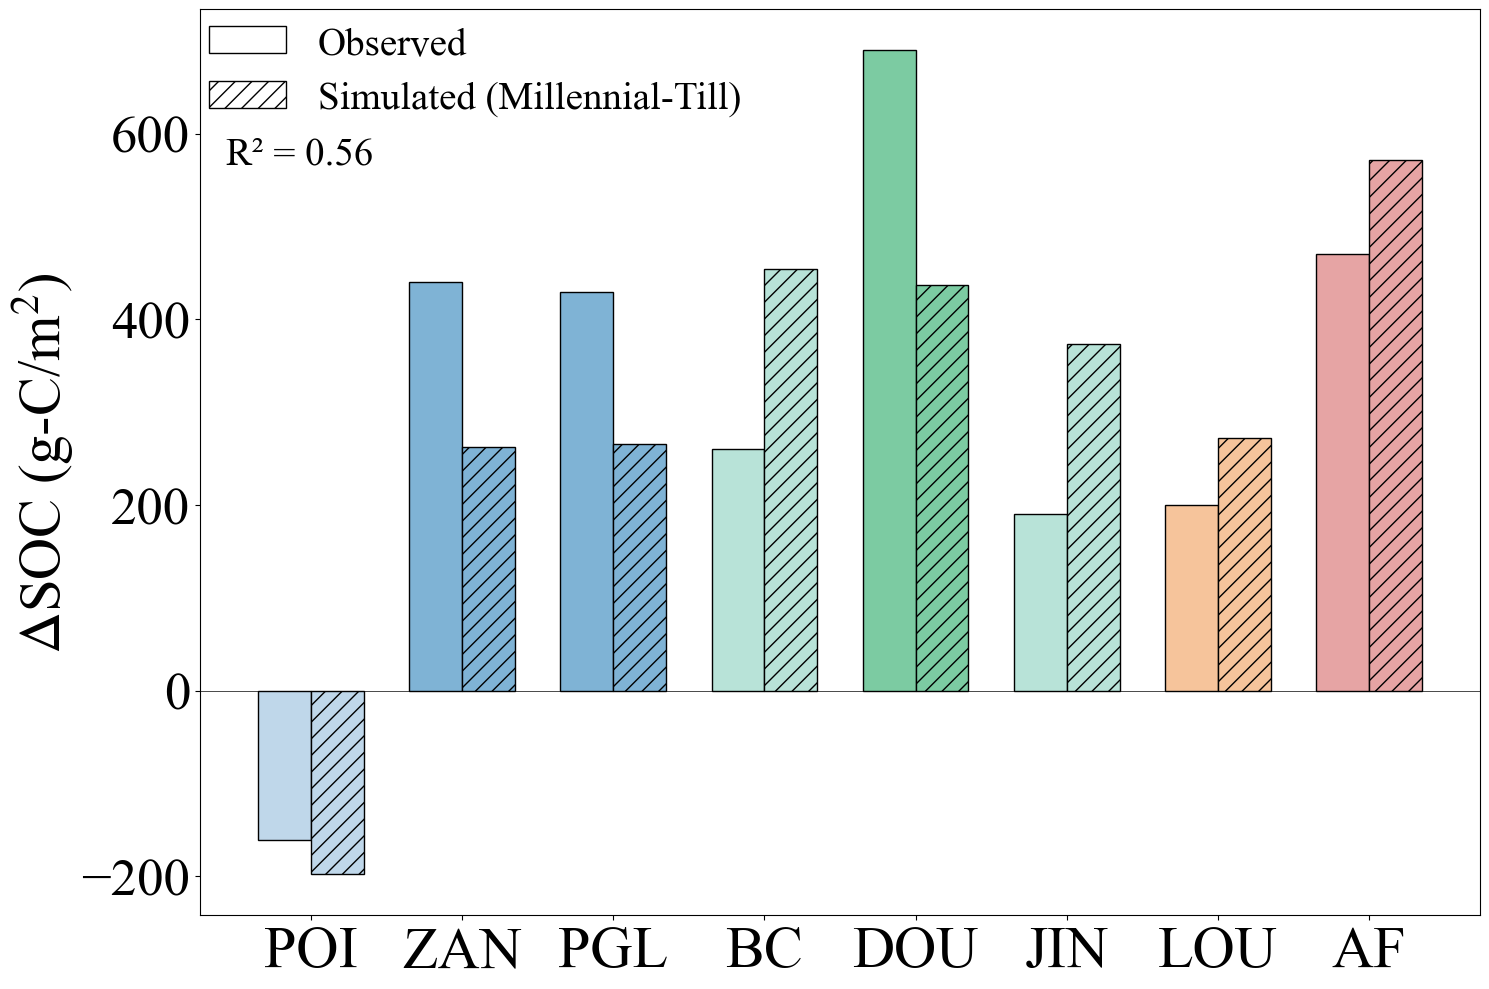

In [12]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from matplotlib.patches import Patch
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# -----------------------
# CONFIG
# -----------------------
folder_path = r'C:\Users\rishabh.singh\OneDrive - Texas A&M AgriLife\Desktop\Slope\Results'
obs_excel = os.path.join(folder_path, "gcb15001-sup-0001-tables1.xlsx")

study_files = ["AF.csv", "BC.csv", "DOU.csv", "POI.csv", "PGL.csv", "ZAN.csv", "JIN.csv", "LOU.csv"]
study_list = [f.replace(".csv", "").strip().upper() for f in study_files]

study_colors = {
    "AF":  "#E6A4A4",
    "BC":  "#B8E3D8",
    "DOU": "#7CCBA2",
    "JIN": "#B8E3D8",
    "LOU": "#F6C49B",
    "POI": "#BFD7EA",
    "PGL": "#7FB3D5",
    "ZAN": "#7FB3D5"
}

mpl.rcParams['font.family'] = 'Times New Roman'
mpl.rcParams['mathtext.fontset'] = 'stix'

CT_START = 720
CT_END   = 770

# -----------------------
# STEP 1: Load Observations
# -----------------------
obs_df = pd.read_excel(obs_excel, sheet_name="SOC")
obs_df.columns = obs_df.columns.str.strip()
obs_df["Study"] = obs_df["Study"].astype(str).str.strip().str.upper()
obs_df["Duration"] = obs_df["Study Duration"]

obs_df = obs_df[obs_df["Study"].isin(study_list)].copy()

# -----------------------
# STEP 2: Process simulations
# -----------------------
sim_results = []

for filename in study_files:
    study = filename.replace(".csv", "").strip().upper()

    if study not in obs_df["Study"].values:
        continue

    duration = int(obs_df.loc[obs_df["Study"] == study, "Duration"].values[0])
    end_year = 800 + duration

    df = pd.read_csv(os.path.join(folder_path, filename))
    df["Year"] = pd.to_numeric(df["Years"], errors="coerce")
    df = df.dropna(subset=["Year"]).sort_values("Year")

    for c in ["A", "P", "DOC", "M", "B"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    df["SOC"] = df[["A", "P", "DOC", "M", "B"]].sum(axis=1)

    # ---- CT window ----
    ct_window = df.loc[df["Year"].between(CT_START, CT_END)]
    if ct_window.empty:
        continue

    CT_SOC = ct_window["SOC"].mean()

    # ---- NT year ----
    if end_year in df["Year"].values:
        NT_SOC = df.loc[df["Year"] == end_year, "SOC"].values[0]
    else:
        NT_SOC = np.interp(end_year, df["Year"], df["SOC"])

    sim_results.append({
        "Study": study,
        "Duration": duration,
        "CT_SOC": CT_SOC,
        "NT_SOC": NT_SOC,
        "Simulated Delta SOC": NT_SOC - CT_SOC
    })

sim_df = pd.DataFrame(sim_results)

# -----------------------
# STEP 3: Merge with observations
# -----------------------
merged_df = pd.merge(obs_df, sim_df, on=["Study", "Duration"], how="inner")

# -----------------------
# R² Calculation
# -----------------------
x = merged_df["Observed Delta SOC"].values.reshape(-1, 1)
y = merged_df["Simulated Delta SOC"].values

model = LinearRegression()
model.fit(x, y)
y_pred = model.predict(x)
r2 = r2_score(y, y_pred)

print(f"\n📈 Regression R² = {r2:.3f}")

# -----------------------
# Restore original AI-based ordering
# -----------------------

def assign_ai_bin(ai):
    if 0.5 <= ai < 1: return '[0.5-1)'
    elif 1 <= ai < 1.5: return '[1-1.5)'
    elif 1.5 <= ai < 2.5: return '[1.5-2.5)'
    elif 2.5 <= ai <= 4: return '[2.5-4)'
    else: return 'Out of range'

merged_df["AI Bin"] = merged_df["AI"].apply(assign_ai_bin)

merged_df["AI Bin"] = pd.Categorical(
    merged_df["AI Bin"],
    categories=['[0.5-1)', '[1-1.5)', '[1.5-2.5)', '[2.5-4)'],
    ordered=True
)

merged_df = merged_df.sort_values(
    ["AI Bin", "AI", "Study"]
).reset_index(drop=True)

# -----------------------
# STEP 4: Plot
# -----------------------
fig, ax = plt.subplots(figsize=(15, 10))
xpos = np.arange(len(merged_df))
width = 0.35

for i, row in merged_df.iterrows():
    study = row["Study"]
    color = study_colors.get(study, "#cccccc")

    # Observed
    ax.bar(
        xpos[i] - width/2,
        row["Observed Delta SOC"],
        width,
        color=color,
        edgecolor="black"
    )

    # Simulated
    ax.bar(
        xpos[i] + width/2,
        row["Simulated Delta SOC"],
        width,
        color=color,
        edgecolor="black",
        hatch="//"
    )

ax.set_ylabel(r"$\Delta$SOC (g-C/m$^2$)", fontsize=42)
ax.set_xticks(xpos)
ax.set_xticklabels(merged_df["Study"], fontsize=42)
ax.tick_params(axis="y", labelsize=38)
ax.axhline(y=0, color="black", linewidth=0.5)

legend_handles = [
    Patch(facecolor="white", edgecolor="black", label="Observed"),
    Patch(facecolor="white", edgecolor="black", hatch="//", label="Simulated (Millennial-Till)")
]

ax.legend(
    handles=legend_handles,
    fontsize=28,
    frameon=False,
    loc='upper right',
    bbox_to_anchor=(0.45, 1.02)
)

ax.text(0.02, 0.829, f"R² = {r2:.2f}",
        transform=ax.transAxes,
        fontsize=28)

plt.tight_layout()
plt.show()